# N151 — Can online health control improve on sustained replay?

Authorized 5 November 2026. N150 established quarter-rate recent replay as a
stronger baseline, particularly under frequent learning. N149 supported replay
content but did not establish a universally better loss objective. N147–148 found
optimistic H1 predictions, over-restrictive absolute gates, and poor update timing.
This experiment tests two causal H1 objectives against fixed replay on new streams.

## Five equal-training-work arms

1. **Fixed replay:** N150 Replay-five, quarter nominal LR (2.5e-5).
2. **Fixed small replay:** the same update at 1/16 nominal LR (6.25e-6).
3. **Random menu:** balanced 96-update warmup, then uniform random menu selection.
4. **Current controller:** online prediction; current-image loss and RankMe objective.
5. **Mixed controller:** identical predictor/selection mechanics; 50/50 current and
   recent-past reconstruction loss plus RankMe objective.

The menu for arms 3–5 is {replay-quarter, replay-sixteenth, current-five-quarter}.
Replay uses .5 first current-view loss + .5 mean loss of four distinct past images.
Current-five replaces those past images with four additional current-image views.
All actions use five gradient images, one Adam step and clipping at 1. LR=1 is
excluded because earlier immediate objectives over-selected large steps without
reliable delayed health. Hold is excluded in this first experiment to test action
quality at equal training work. This is not a compute-saving admission experiment.

All arms update on every arrival from index 255 to 4543: **4,289 steps and 21,445
gradient images each**. Same initial full model/Adam state and per-arrival training
seeds. First and second training draws/shapes match across arms. Learning-rate
sequences can differ; equal gradient work does not mean equal LR dose or wall time.
Fixed-small and random controls contextualize those differences. Random-menu action
counts are not matched to either controller; it is not an exact action-mix ablation.

## Causal controller state and objective

At each update, deterministically sample four replay images and a disjoint 64-image
controller bank from the previous 256 arrivals, excluding the initial audit bank.
Sampling depends only on past identity and the fixed seed. All arms use the same
identities. The bank is disjoint from this step's replay, but can have been trained
on in earlier steps: it is policy context, not an independent generalization audit.

Before and after the executed update, evaluate the same fixed-mask current image,
the same 64-image past bank, and freshly encode the bank plus the incoming image.
The target is the relative H1 change in [current loss, past loss, RankMe]. RankMe
is the existing uncentered spectrum definition on 65 embeddings, including the
would-be embedding of the current image. Its scale differs from the 256-image audit.
RankMe is a population property; current-image health additionally uses norm and
pre/post embedding cosine. Do not interpret singleton RankMe as meaningful.

For predicted relative changes d_c, d_p, d_r, minimize

    J_w = w*(1+d_c) + (1-w)*(1+d_p) + 1/(1+d_r)

w=1 for Current; w=.5 for Mixed. This normalizes each loss by its own current
reading. Both losses and inverse RankMe have total unit weight. This defines
selection only; report observed loss and RankMe separately when evaluating arms.

Replay-quarter is the default. An alternative must have physically positive
predicted readings, improve J beyond an error-based margin, and pass a relative
RankMe check against predicted replay. For each action use the most recent 256
chosen-action prediction residuals (relative observed change minus prediction).
Let q_J be the 90th percentile absolute first-order score residual
|w*e_c+(1-w)*e_p-e_r|; let q_R be the 90th percentile |e_r|.
Require J_replay-J_action > .25*(q_J_action+q_J_replay), and predicted rank change
>= predicted replay rank change - .5*(q_R_action+q_R_replay). Among eligible actions
choose lowest J; otherwise execute replay-quarter. Ties favor the default.

These locked coefficients are exploratory policy choices, not tuned on these
streams. Residual tolerances are heuristics, not confidence intervals or coverage
guarantees. The rank check is relative to replay, not a promise of nondecreasing
absolute RankMe. There is no fixed +5 requirement, absolute .001 loss threshold,
performance-triggered rollback, or post-action rejection. Report violations.

## Predictor is online learned

No offline predictor or pretrained controller transfers into N151. Arms 3–5 start
with 96 updates cycling the three actions (32 each); scientific outcomes include
that learning cost. Then controllers explore one seeded uniform action every 16
updates (6.25% exploration slots) and use their objective otherwise. Exploration
and warmup deliberately bypass the score/rank gate; report them separately.

Each action has a regularized linear model for three relative H1 changes. Seventeen
features are log current loss, log bank loss, log RankMe, log current norm, cosine
to mean bank embedding, RGB means/stds, previous three relative changes, and previous
action one-hot. Fit feature scales on the first 96 observations only, floor scale
at 1e-4, clip standardized inputs to [-5,5]. Ridge alpha=10 (intercept penalty=1).
Discount action-specific sufficient statistics with half-life 256 observations of
that action. Only the executed action supplies a target. Predictions are saved
before execution; online errors are saved before incorporating their target.
Initialize residual histories with warmup ridge leave-one-out/PRESS residuals.

Fixed arms fit the same head for measurement bookkeeping, but never consult it for
decisions. Their unobserved-action heads have no scientific interpretation. All
arms receive identical health measurement overhead for this diagnostic; report
training, measurement, head and audit times separately. A production fixed replay
baseline would not require the controller's measurement/head overhead.

## Data and evaluation

N106 reserved clips [684:828]: three ordered 48-clip streams, 4,608 images each,
unused by N145–N150. Verify pixel uniqueness, no cross-stream/prior overlap, and no
old-bank overlap. These are new experiment streams within a historically inspected
dataset, not a new external benchmark. Start all 15 trajectories at the same
original parent; use one paired seed configuration per stream.

First 255 arrivals have no updates. Select 64 initial-context audit images from
that prefix (seeds 151101/151201/151301); exclude them from training, replay and
controller-bank sampling. Reserve last 64 images (4544..4607) as unseen future
tail, evaluated only at the final state. No audit enters prediction or selection.

Primary comparisons: each controller versus fixed replay on the same stream:
- Mean incoming reconstruction BEFORE training, arrivals 255..4543.
- Final reserved initial-context reconstruction and RankMe.
- Final unseen-tail reconstruction and RankMe.

Also report older fixed-bank and latest-256 health at parent/every 384 arrivals/final;
full trajectories and common-checkpoint means; actual current-image loss before
and after, embedding norm/cosine, sampled-bank loss and 65-image RankMe before/after;
action counts, LR dose, prediction error versus zero-change persistence, and costs.
Prediction errors refer to selected actions, not unobserved counterfactual accuracy.
Exploration and objective-selected predictions are distinguished in diagnostics.
Report per-stream paired effects and equally weighted three-stream means after
matched paths finish. No best-checkpoint selection or combined evaluation winner
score. No task labels, probes, kNN or fine-tuning.

## What this answers

If Mixed beats fixed replay across adaptation and retained health, and improves on
Current, recent-past loss has useful online selection value. If both controllers
beat replay similarly, action selection helps but the mixed objective is not yet
the explanation. If fixed-small or random matches them, simpler action/dose changes
may suffice. If controllers remain near baseline, inspect switches, calibration
and exploration costs before claiming either objective has been disproven. If they
lose despite good chosen-action H1 accuracy, the immediate objective/horizon is
still suspect. Good local predictions alone do not establish better long trajectories.

Three streams sharing one parent give descriptive evidence; frames are not
independent replicates. This experiment does not establish optimal weights,
uncertainty coverage, task quality or compute-saving hold decisions.

## Reliability and background operation

Preserve all older frozen experiment files. CPU tests cover causal roles, objective
selection, warmup balance, online update and resume. GPU preflight tests every arm
uninterrupted versus resumed, including exact network/Adam/RNG, full online head,
trace and audit equality; verifies N150 replay equivalence and matched RNG/work.
The engineering stream uses six warmup updates to exercise the transition quickly;
the scientific protocol remains 96, covered separately by a unit test.

Freeze inputs/source and snapshot source before scientific training. Save full
network/Adam/RNG/head/trace every 96 arrivals, retain two valid generations, respect
stop-request.json and a 1 GiB disk reserve. Notebook 151 embeds this protocol first,
refreshes plots after checkpoints, and has a localhost report on port 8851.


# N151 — Online health control versus sustained replay

Status: **complete**. Completed 15/15 trajectories.

Active: engineering / preparation, 0/4544 arrivals.

All arms use five gradient images per update. LR dose and controller overhead can differ. Partial rows have different coverage and are not final comparisons.

## stream_a

| Arm | Arrivals | Updates | Actions: replay / small / current | Incoming pre-loss | Initial loss | Initial RankMe |
|---|---:|---:|---|---:|---:|---:|
| fixed_replay | 4544 | 4289 | 4289 / 0 / 0 | 0.8274947143873987 | 0.712400 | 2.566170 |
| fixed_small_replay | 4544 | 4289 | 0 / 4289 / 0 | 0.8576510003686479 | 0.729728 | 2.549849 |
| random_menu | 4544 | 4289 | 1420 / 1461 / 1408 | 0.8348467345559033 | 0.705897 | 2.568110 |
| current_controller | 4544 | 4289 | 3336 / 792 / 161 | 0.8330498632364102 | 0.706702 | 2.490137 |
| mixed_controller | 4544 | 4289 | 3042 / 1099 / 148 | 0.8351794131487559 | 0.704218 | 2.558068 |

Completed contrast: **fixed_small_replay** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.017328 | -0.016320 |
| future_tail | -0.017295 | -0.004943 |
| historical | -0.004054 | -1.440168 |
| recent | -0.026327 | -0.724170 |

Incoming pre-update loss advantage: -0.030156.

Completed contrast: **random_menu** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.006503 | +0.001940 |
| future_tail | -0.001214 | +0.002728 |
| historical | -0.006118 | +0.248338 |
| recent | -0.008274 | -0.334202 |

Incoming pre-update loss advantage: -0.007352.

Completed contrast: **current_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.005698 | -0.076033 |
| future_tail | +0.002015 | +0.001026 |
| historical | -0.002042 | +0.587581 |
| recent | -0.000581 | -0.351789 |

Incoming pre-update loss advantage: -0.005555.

Completed contrast: **mixed_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.008182 | -0.008102 |
| future_tail | -0.000783 | +0.003404 |
| historical | -0.001800 | +0.659925 |
| recent | -0.002240 | -0.184913 |

Incoming pre-update loss advantage: -0.007685.

Completed contrast: **mixed_vs_current** minus current-controller (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.002485 | +0.067931 |
| future_tail | -0.002798 | +0.002378 |
| historical | +0.000242 | +0.072344 |
| recent | -0.001659 | +0.166875 |

Incoming pre-update loss advantage: -0.002130.

current_controller: online targets=4289; objective switches=721; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 263, 'objective': 3930}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0016982575907687788, 0.0007047381033110266, 0.0009714353281375659]; zero-change RMSE: [0.0035274861766213623, 0.0007011629314994641, 0.0021531864869870133].

mixed_controller: online targets=4289; objective switches=1015; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 263, 'objective': 3930}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.001778169602171082, 0.0006700880602700589, 0.001008834541408794]; zero-change RMSE: [0.0035486043395988607, 0.0006441759756214176, 0.002136601924342322].

## stream_b

| Arm | Arrivals | Updates | Actions: replay / small / current | Incoming pre-loss | Initial loss | Initial RankMe |
|---|---:|---:|---|---:|---:|---:|
| fixed_replay | 4544 | 4289 | 4289 / 0 / 0 | 0.8194665252453632 | 0.800641 | 1.918014 |
| fixed_small_replay | 4544 | 4289 | 0 / 4289 / 0 | 0.8448155809738442 | 0.822330 | 2.038091 |
| random_menu | 4544 | 4289 | 1435 / 1426 / 1428 | 0.8276589524290117 | 0.801886 | 2.212477 |
| current_controller | 4544 | 4289 | 3415 / 678 / 196 | 0.8234105608865747 | 0.802632 | 1.935265 |
| mixed_controller | 4544 | 4289 | 3242 / 833 / 214 | 0.8241152962095172 | 0.800687 | 2.025063 |

Completed contrast: **fixed_small_replay** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.021689 | +0.120077 |
| future_tail | +0.004138 | -0.008309 |
| historical | -0.012394 | +1.409880 |
| recent | -0.051579 | +0.920896 |

Incoming pre-update loss advantage: -0.025349.

Completed contrast: **random_menu** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.001245 | +0.294463 |
| future_tail | +0.007592 | +0.091653 |
| historical | -0.003728 | +1.425813 |
| recent | -0.028526 | +0.952472 |

Incoming pre-update loss advantage: -0.008192.

Completed contrast: **current_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.001992 | +0.017250 |
| future_tail | -0.006567 | +0.202547 |
| historical | +0.003466 | +0.841930 |
| recent | -0.001767 | +0.765908 |

Incoming pre-update loss advantage: -0.003944.

Completed contrast: **mixed_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.000047 | +0.107049 |
| future_tail | +0.002130 | +0.103872 |
| historical | +0.001152 | +1.474401 |
| recent | -0.011130 | +0.746406 |

Incoming pre-update loss advantage: -0.004649.

Completed contrast: **mixed_vs_current** minus current-controller (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.001945 | +0.089799 |
| future_tail | +0.008697 | -0.098675 |
| historical | -0.002314 | +0.632471 |
| recent | -0.009363 | -0.019502 |

Incoming pre-update loss advantage: -0.000705.

current_controller: online targets=4289; objective switches=622; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 263, 'objective': 3930}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0010475914100893703, 0.0006422720845192508, 0.0010628991172739698]; zero-change RMSE: [0.002638481630049124, 0.0007793143954312565, 0.0019215111035959967].

mixed_controller: online targets=4289; objective switches=795; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 263, 'objective': 3930}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0010597082205817169, 0.0006205091316082439, 0.0015573864283467027]; zero-change RMSE: [0.0025086097687004446, 0.0006989925826979264, 0.0024820349179669686].

## stream_c

| Arm | Arrivals | Updates | Actions: replay / small / current | Incoming pre-loss | Initial loss | Initial RankMe |
|---|---:|---:|---|---:|---:|---:|
| fixed_replay | 4544 | 4289 | 4289 / 0 / 0 | 0.8126867465356981 | 0.858666 | 1.774941 |
| fixed_small_replay | 4544 | 4289 | 0 / 4289 / 0 | 0.8449917999242785 | 0.853583 | 1.932967 |
| random_menu | 4544 | 4289 | 1445 / 1436 / 1408 | 0.8209446100025195 | 0.850569 | 1.795322 |
| current_controller | 4544 | 4289 | 3312 / 776 / 201 | 0.8190979268632032 | 0.847092 | 1.918777 |
| mixed_controller | 4544 | 4289 | 3078 / 1048 / 163 | 0.8212898601238253 | 0.844398 | 1.991707 |

Completed contrast: **fixed_small_replay** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.005083 | +0.158027 |
| future_tail | +0.002612 | +0.078604 |
| historical | +0.005774 | -0.367739 |
| recent | -0.024639 | -0.016850 |

Incoming pre-update loss advantage: -0.032305.

Completed contrast: **random_menu** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.008097 | +0.020382 |
| future_tail | -0.000653 | -0.010690 |
| historical | +0.010585 | -0.805986 |
| recent | -0.012667 | -0.416508 |

Incoming pre-update loss advantage: -0.008258.

Completed contrast: **current_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.011574 | +0.143837 |
| future_tail | +0.002470 | +0.086483 |
| historical | +0.013796 | +2.977795 |
| recent | +0.001315 | +2.254721 |

Incoming pre-update loss advantage: -0.006411.

Completed contrast: **mixed_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.014268 | +0.216766 |
| future_tail | +0.005653 | +0.157346 |
| historical | +0.013699 | +3.490038 |
| recent | +0.000064 | +2.370843 |

Incoming pre-update loss advantage: -0.008603.

Completed contrast: **mixed_vs_current** minus current-controller (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.002694 | +0.072929 |
| future_tail | +0.003183 | +0.070862 |
| historical | -0.000096 | +0.512243 |
| recent | -0.001251 | +0.116122 |

Incoming pre-update loss advantage: -0.002192.

current_controller: online targets=4289; objective switches=758; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 263, 'objective': 3930}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0011131859654603552, 0.0005170639302787203, 0.001267362057693073]; zero-change RMSE: [0.002735137426443574, 0.0006664394284572148, 0.00266556257747146].

mixed_controller: online targets=4289; objective switches=992; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 263, 'objective': 3930}.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.000988629236145795, 0.0004950274212024412, 0.0012030694510442518]; zero-change RMSE: [0.0025478795187995093, 0.0006263814098246247, 0.0023612778560930824].

## Completed three-stream mean: fixed_small_replay

Incoming pre-loss advantage: -0.029270.

- initial: loss -0.011311; RankMe +0.087261
- future_tail: loss -0.003515; RankMe +0.021784
- historical: loss -0.003558; RankMe -0.132676
- recent: loss -0.034181; RankMe +0.059959

## Completed three-stream mean: random_menu

Incoming pre-loss advantage: -0.007934.

- initial: loss +0.004451; RankMe +0.105595
- future_tail: loss +0.001908; RankMe +0.027897
- historical: loss +0.000246; RankMe +0.289388
- recent: loss -0.016489; RankMe +0.067254

## Completed three-stream mean: current_controller

Incoming pre-loss advantage: -0.005303.

- initial: loss +0.005093; RankMe +0.028351
- future_tail: loss -0.000694; RankMe +0.096686
- historical: loss +0.005073; RankMe +1.469102
- recent: loss -0.000344; RankMe +0.889614

## Completed three-stream mean: mixed_controller

Incoming pre-loss advantage: -0.006979.

- initial: loss +0.007468; RankMe +0.105238
- future_tail: loss +0.002334; RankMe +0.088207
- historical: loss +0.004351; RankMe +1.874788
- recent: loss -0.004435; RankMe +0.977445

## Completed three-stream mean: mixed_vs_current

Incoming pre-loss advantage: -0.001675.

- initial: loss +0.002375; RankMe +0.076886
- future_tail: loss +0.003027; RankMe -0.008478
- historical: loss -0.000723; RankMe +0.405686
- recent: loss -0.004091; RankMe +0.087832

No labels/probes/kNN. Selected-action prediction accuracy does not measure unobserved counterfactuals. Compare health populations separately; three streams share one parent.


### Actual incoming-image loss and health
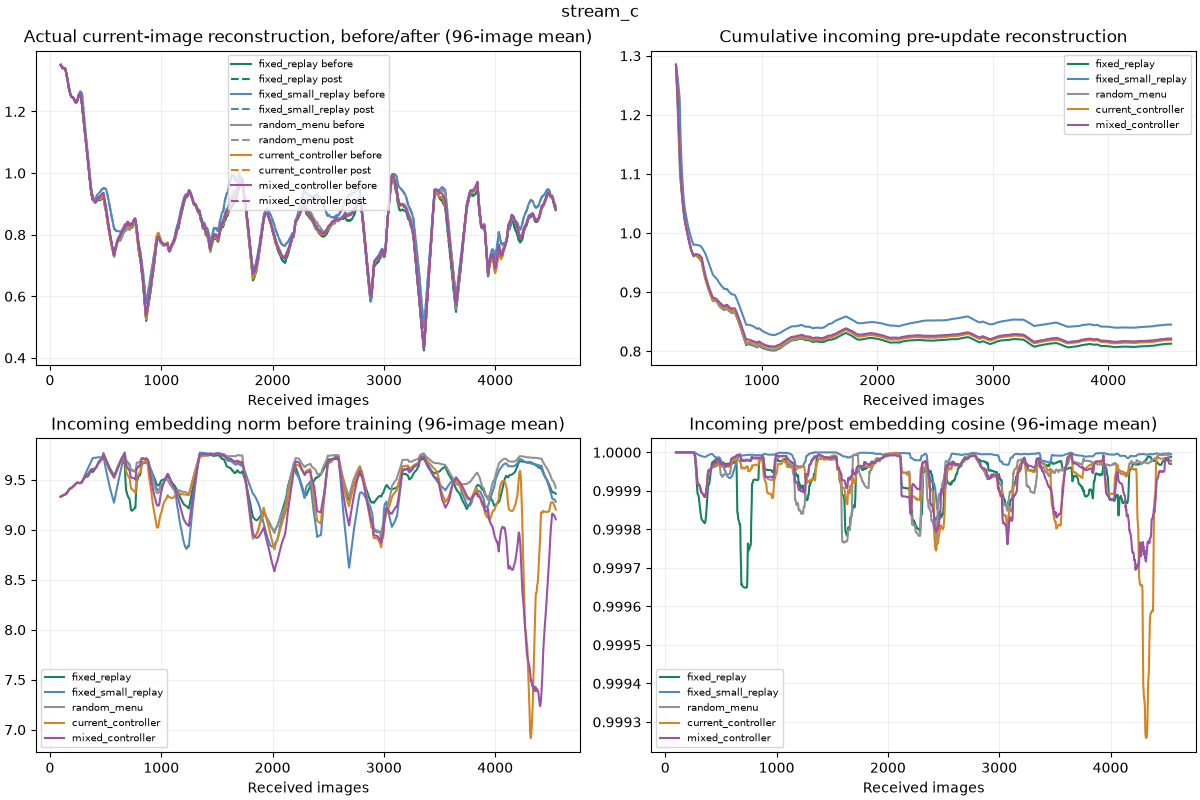

### Retained and recent population health
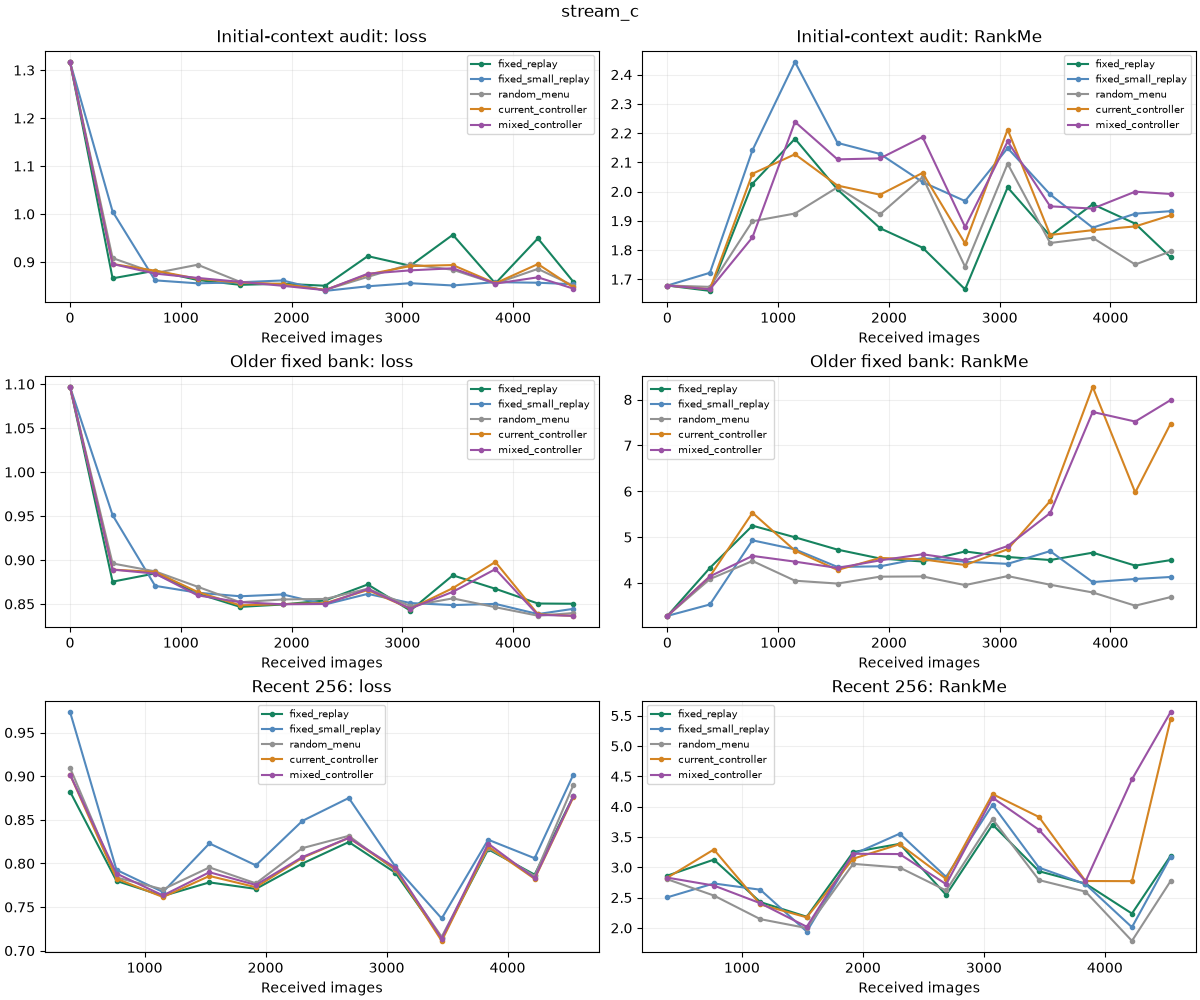

### Actual controller health, actions and LR dose
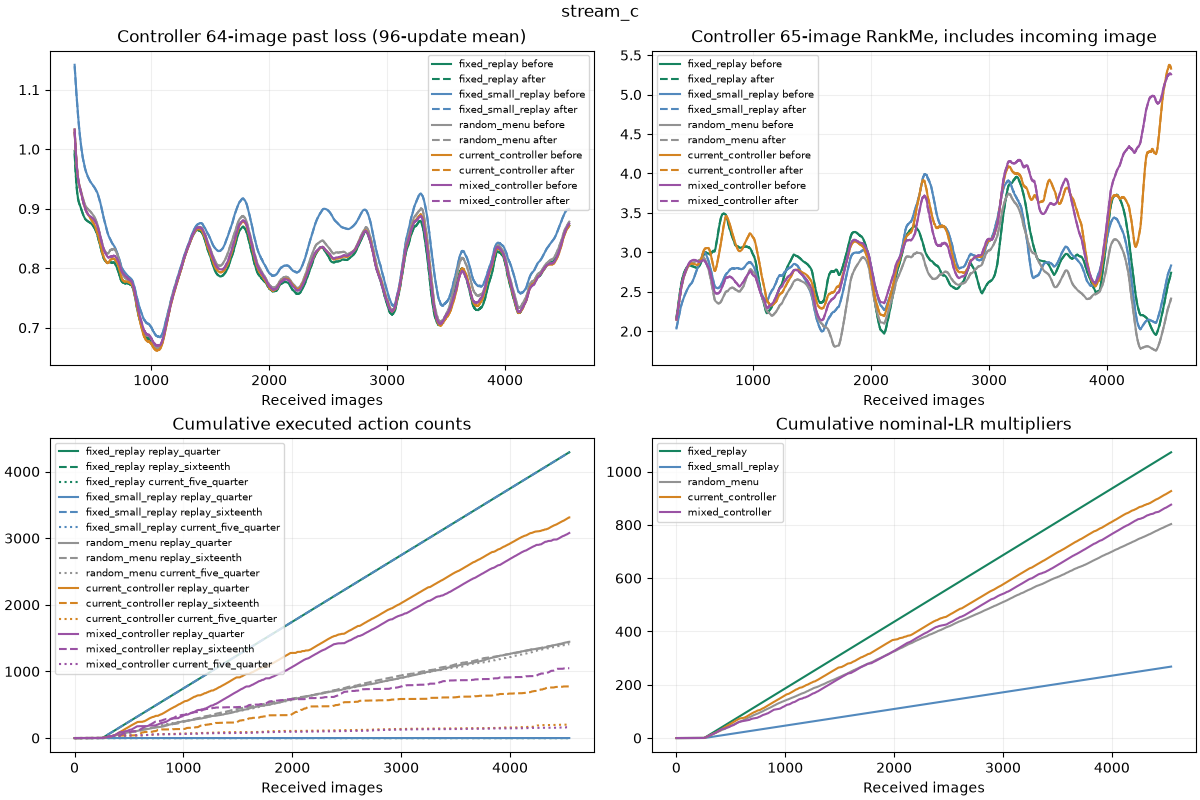

### stream_a: incoming (completed)
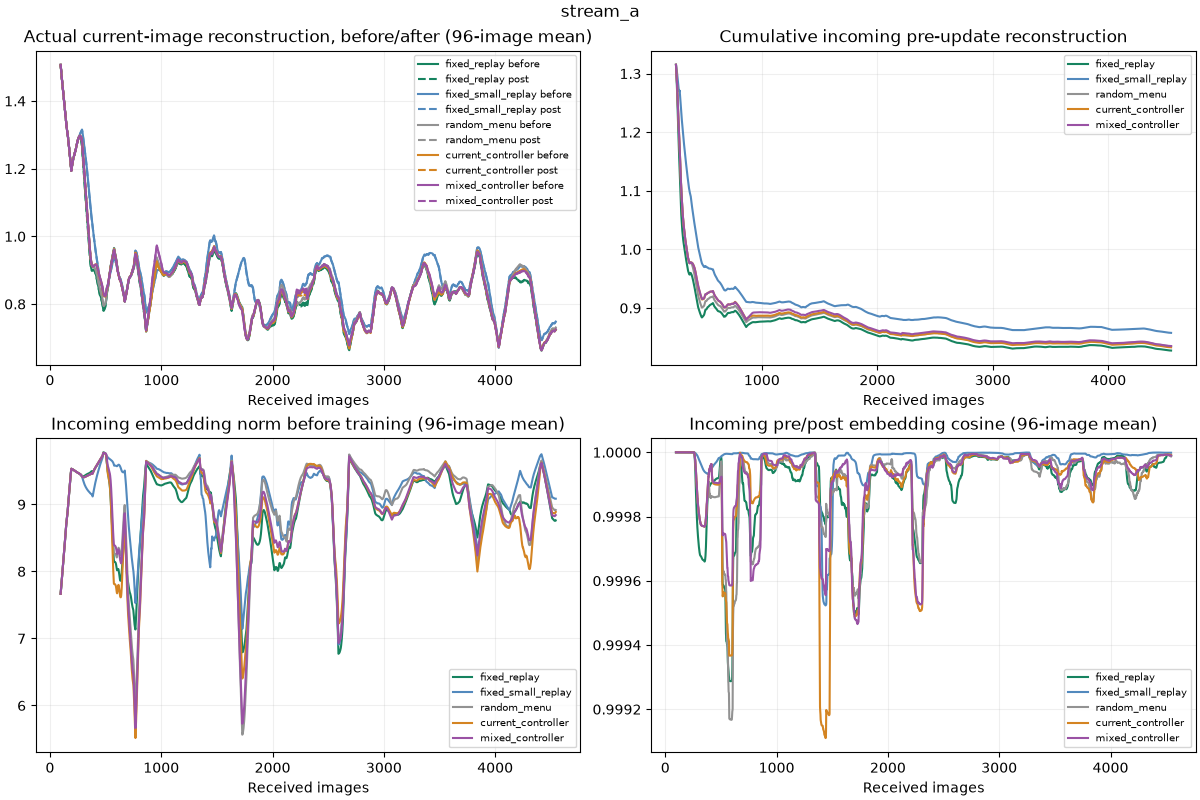

### stream_a: audits (completed)
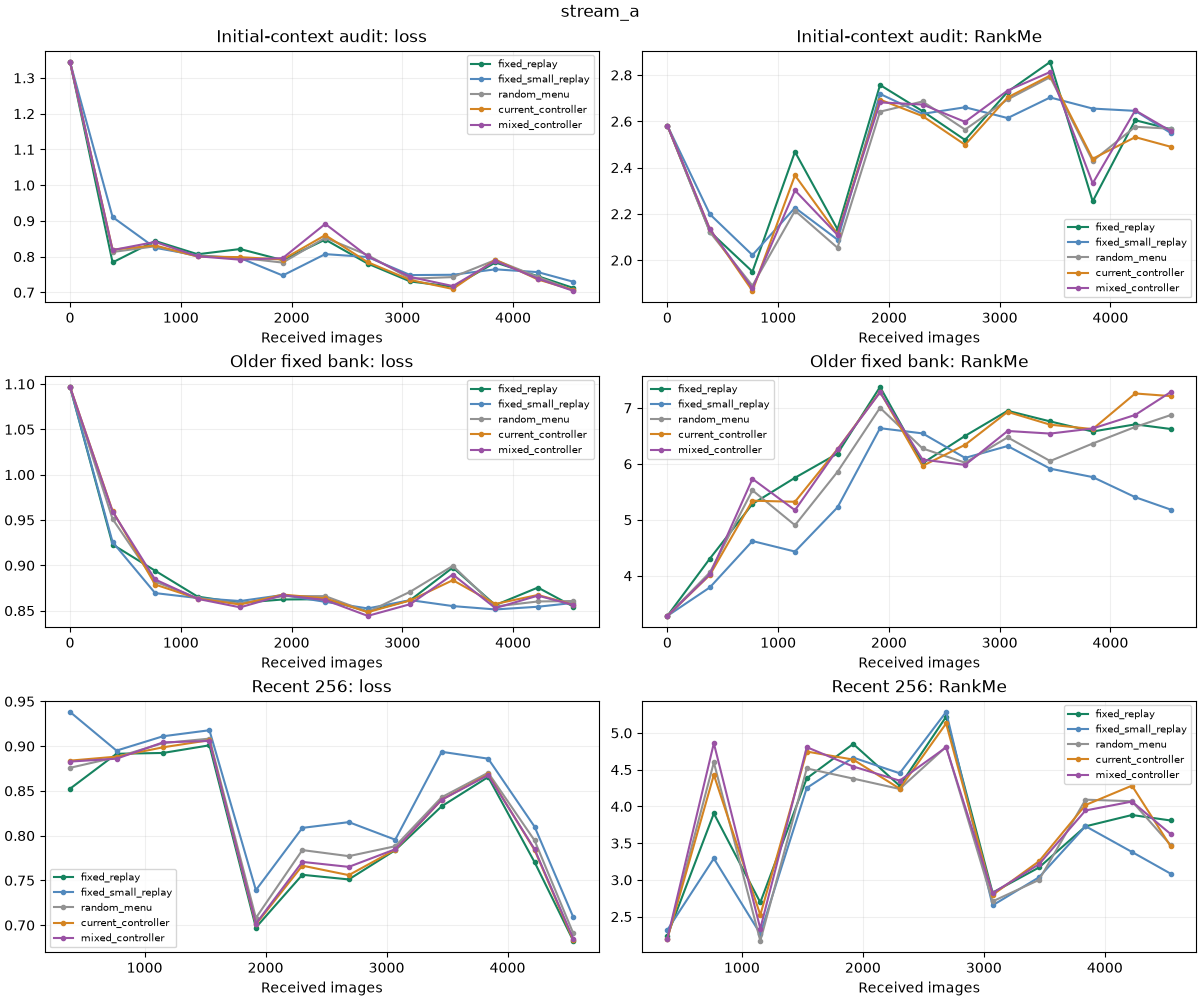

### stream_a: control (completed)
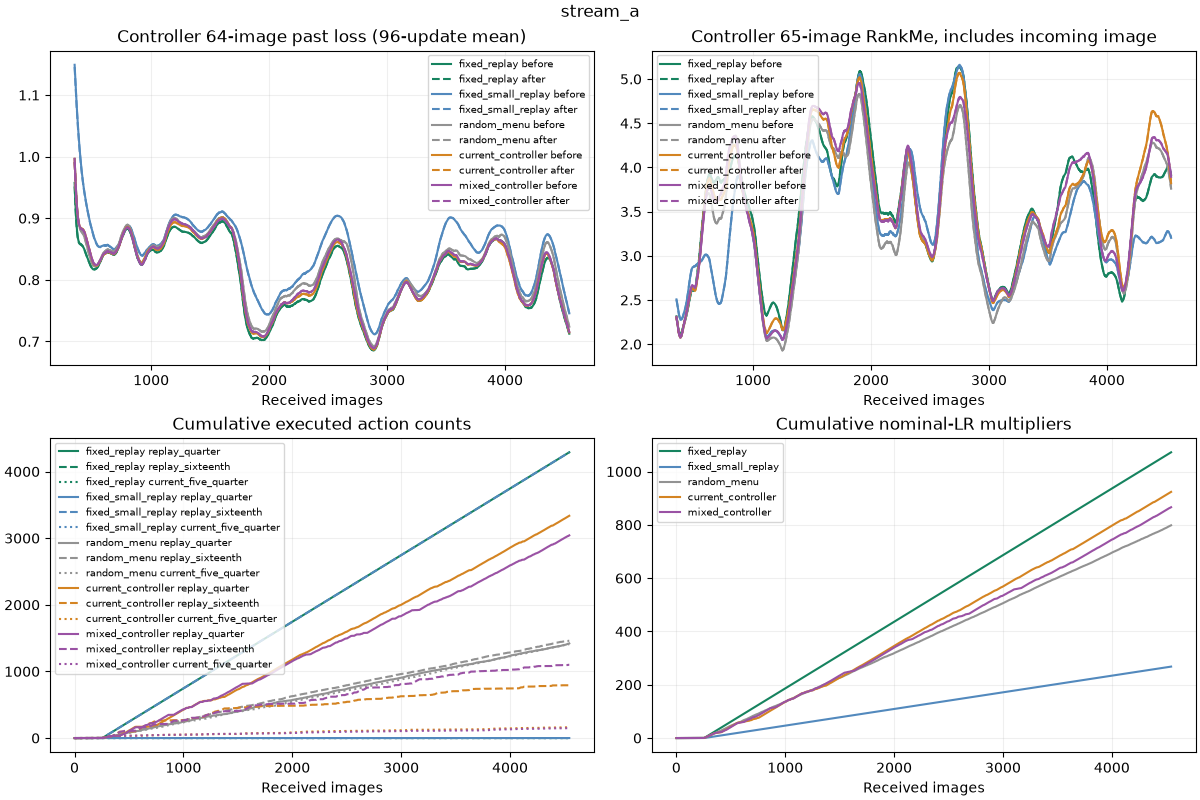

### stream_b: incoming (completed)
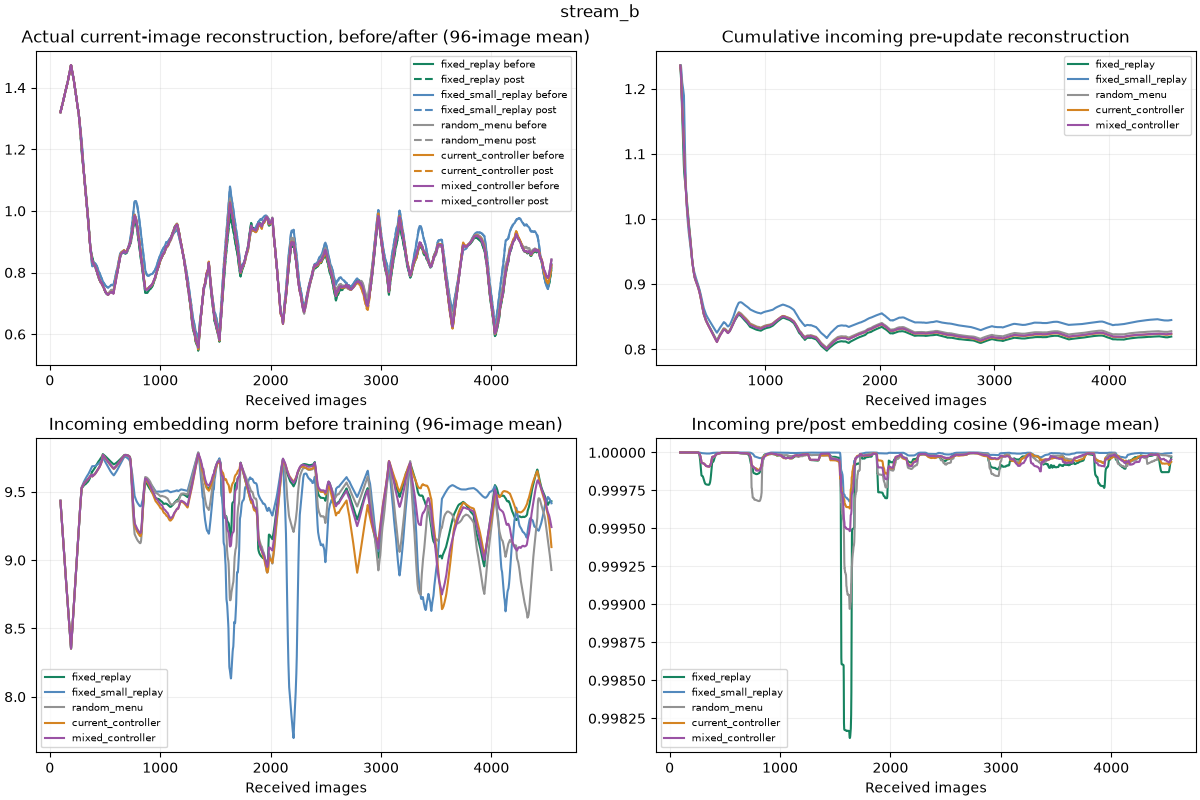

### stream_b: audits (completed)
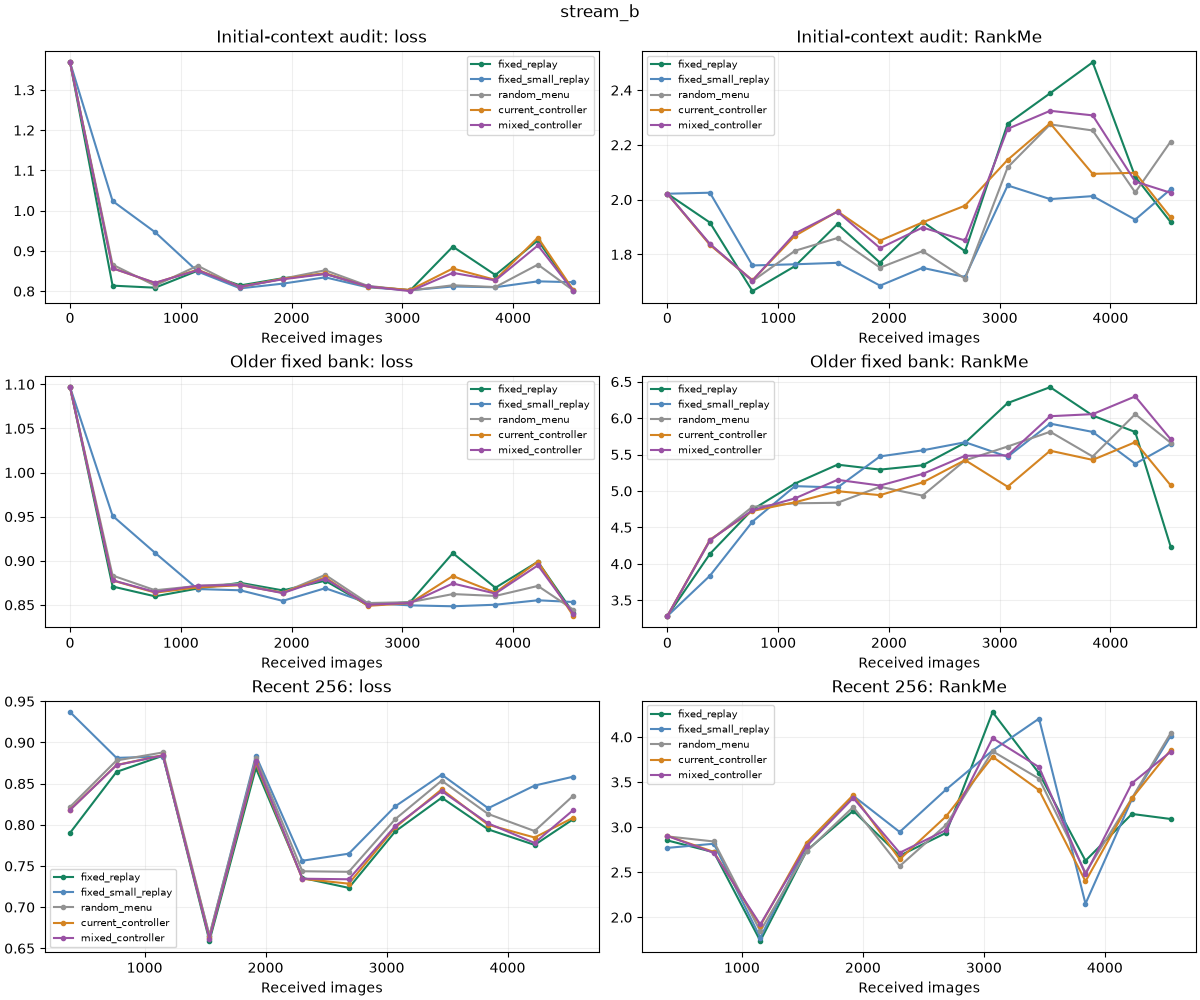

### stream_b: control (completed)
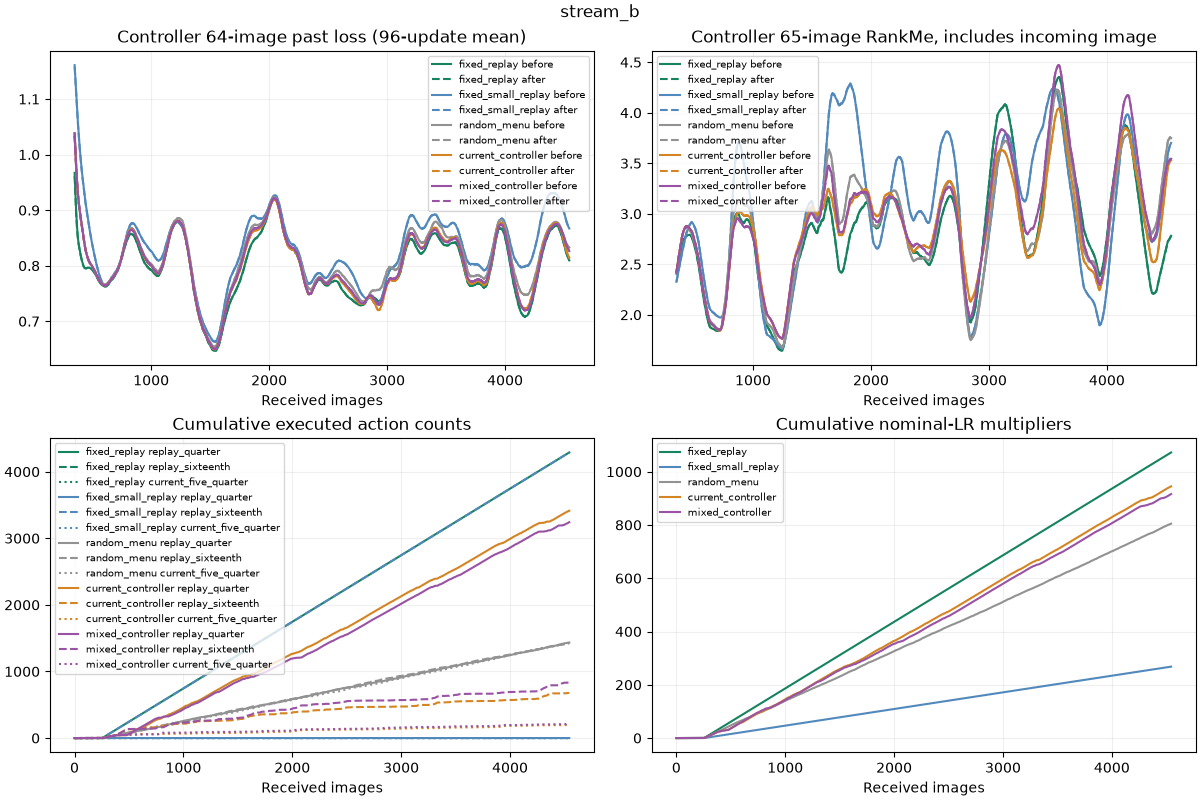